# 决策树与集成学习｜课堂实验
主要内容如下：
1. 决策树调用与参数　2. 树结构与决策边界　3. 动漫轮廓逼近　4. 三种集成调用　5. AdaBoost 逐轮观察

若缺少依赖，在新单元格运行：`%pip install numpy pandas matplotlib scipy pillow scikit-learn ipython`。安装后重启内核。

In [1]:

# 导入 numpy（简称 np），供后续实验调用。
import numpy as np
# 导入 pandas（简称 pd），供后续实验调用。
import pandas as pd
# 导入 matplotlib.pyplot（简称 plt），供后续实验调用。
import matplotlib.pyplot as plt
# 导入 font_manager，来自 matplotlib，供后续实验调用。
from matplotlib import font_manager
# 导入 ListedColormap，来自 matplotlib.colors，供后续实验调用。
from matplotlib.colors import ListedColormap
# 导入 Path，来自 pathlib，供后续实验调用。
from pathlib import Path
# 导入 Image，来自 PIL，供后续实验调用。
from PIL import Image
# 导入 ndimage，来自 scipy，供后续实验调用。
from scipy import ndimage
# 导入 display，来自 IPython.display，供后续实验调用。
from IPython.display import display
# 导入 make_moons，来自 sklearn.datasets，供后续实验调用。
from sklearn.datasets import make_moons
# 导入 train_test_split, StratifiedKFold, cross_val_predict，来自 sklearn.model_selection，供后续实验调用。
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
# 导入 DecisionTreeClassifier, DecisionTreeRegressor, plot_tree，来自 sklearn.tree，供后续实验调用。
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
# 导入 BaggingClassifier, AdaBoostClassifier, StackingClassifier，来自 sklearn.ensemble，供后续实验调用。
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, StackingClassifier
# 导入 LogisticRegression，来自 sklearn.linear_model，供后续实验调用。
from sklearn.linear_model import LogisticRegression
# 导入 KNeighborsClassifier，来自 sklearn.neighbors，供后续实验调用。
from sklearn.neighbors import KNeighborsClassifier
# 导入 make_pipeline，来自 sklearn.pipeline，供后续实验调用。
from sklearn.pipeline import make_pipeline
# 导入 StandardScaler，来自 sklearn.preprocessing，供后续实验调用。
from sklearn.preprocessing import StandardScaler
# 导入 clone，来自 sklearn.base，供后续实验调用。
from sklearn.base import clone
# 导入 accuracy_score, mean_squared_error，来自 sklearn.metrics，供后续实验调用。
from sklearn.metrics import accuracy_score, mean_squared_error
# 导入 sklearn，供后续实验调用。
import sklearn
# 导入 inspect，供后续实验调用。
import inspect
# 导入 base64，供后续实验调用。
import base64
# 导入 io，供后续实验调用。
import io

SEED = 42  # 固定随机种子，保证课堂上重复运行时结果一致。
# 创建指定种子的随机数生成器，使随机采样结果可复现。
rng = np.random.default_rng(SEED)

# 自动寻找中文字体；若本机没有，可安装 Noto Sans CJK SC 或使用 Windows 的微软雅黑。
# 计算并保存 font_names，供后续数据处理、模型训练或结果展示使用。
font_names = {f.name for f in font_manager.fontManager.ttflist}
# 循环流程：按候选顺序查找本机已安装的中文字体，找到后采用；均未找到时提示安装字体。
for name in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Noto Sans CJK JP', 'Noto Serif CJK JP', 'WenQuanYi Micro Hei', 'Arial Unicode MS']:
    if name in font_names:
        plt.rcParams['font.sans-serif'] = [name]
        break
else:
    print('未找到中文字体：请安装中文字体后重启内核，或将图中文字改为英文。')
# 执行当前数据处理操作，为后续实验准备结果。
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 110, 'font.size': 11})
# 计算并保存 CMAP，供后续数据处理、模型训练或结果展示使用。
CMAP = ListedColormap(['#68a9c9', '#e9a268'])
# 输出当前实验的参数、数据规模或评估结果。
print('scikit-learn 版本：', sklearn.__version__)

scikit-learn 版本： 1.8.0


## 实验 1｜决策树的调用与参数

| 参数 | 本实验中的含义 |
|---|---|
| `criterion` | 分类用 `gini` 或 `entropy`；回归示例用 `squared_error` |
| `max_depth` | 最大深度，根节点深度为 0；`None` 不主动限制深度 |
| `min_samples_split` | 节点至少包含多少样本，才允许继续分裂 |
| `min_samples_leaf` | 每个叶节点至少保留多少样本 |
| `max_features` | 每次分裂考虑的特征数；这里用 `None`，考虑全部特征 |
| `ccp_alpha` | 剪枝强度；这里用 0，不进行代价复杂度剪枝 |
| `random_state` | 控制随机因素，方便复现 |

先用带少量噪声的二维双月牙数据。后续分类实验复用同一划分；测试集只作课堂观察，不用于选参数。

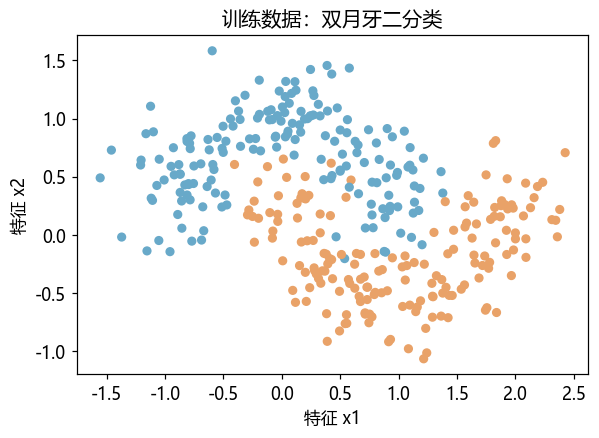

,真实类别,预测类别,P(类别0),P(类别1)
0,1,1,0.010000,0.990000
1,1,1,0.010000,0.990000
2,0,0,0.847458,0.152542
3,0,0,1.000000,0.000000
4,1,1,0.233766,0.766234
5,0,0,0.847458,0.152542


深度=3，叶节点=6，测试准确率=0.887


In [2]:

# 构造二维分类数据，保留固定测试集，便于各模型之间比较。
# 生成带噪声的双月牙二分类数据，X 是二维特征，y 是类别标签。
X, y = make_moons(n_samples=500, noise=0.23, random_state=SEED)
# 将样本及对应标签同步划分为训练集和测试集；stratify 用于保持类别比例。
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
# 创建画布和子图坐标轴，供后续绘图使用。
fig, ax = plt.subplots(figsize=(6, 4))
# 绘制散点；位置表示两个特征，颜色或大小用于区分类别、权重或指定样本。
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=CMAP, s=25)
# 设置子图标题、坐标轴标签或显示范围。
ax.set(xlabel='特征 x1', ylabel='特征 x2', title='训练数据：双月牙二分类')
# 显示当前绘制的图形。
plt.show()

# 设定树的复杂度，再用 fit 训练；分类树不要求先标准化特征。
# 创建分类决策树；max_depth 限制深度，min_samples_leaf 限制叶节点最少样本数。
tree = DecisionTreeClassifier(
    criterion='gini', max_depth=3, min_samples_split=2,
    min_samples_leaf=5, max_features=None, ccp_alpha=0.0, random_state=SEED
)
# 使用给定特征和标签训练模型，学习特征与目标之间的关系。
tree.fit(X_train, y_train)
# 使用训练好的模型预测输入样本的类别或连续数值。
pred = tree.predict(X_test)
# 计算各样本属于每个类别的概率，每列对应一个类别。
proba = tree.predict_proba(X_test)
# 在 Notebook 中展示结果表格，便于查看和比较。
display(pd.DataFrame({'真实类别': y_test[:6], '预测类别': pred[:6],
                      'P(类别0)': proba[:6, 0], 'P(类别1)': proba[:6, 1]}))
# 输出当前实验的参数、数据规模或评估结果。
print(f'深度={tree.get_depth()}，叶节点={tree.get_n_leaves()}，测试准确率={accuracy_score(y_test, pred):.3f}')

In [3]:

# 固定同一组数据，只改变复杂度参数，比较训练与测试结果。
# 准备 rows，保存后续实验使用的配置、模型或结果记录。
rows = []
# 循环流程：依次执行 DecisionTreeClassifier、fit、append、str、get_depth、get_n_leaves、score，完成该组实验操作。
for depth, leaf_size in [(1, 1), (3, 1), (6, 1), (None, 1), (None, 15)]:
    model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf_size, random_state=SEED)
    model.fit(X_train, y_train)
    rows.append({'max_depth': str(depth), 'min_samples_leaf': leaf_size,
                 '实际深度': model.get_depth(), '叶节点数': model.get_n_leaves(),
                 '训练准确率': model.score(X_train, y_train), '测试准确率': model.score(X_test, y_test)})
# 在 Notebook 中展示结果表格，便于查看和比较。
display(pd.DataFrame(rows).round(3))

,max_depth,min_samples_leaf,实际深度,叶节点数,训练准确率,测试准确率
0,1,1,1,2,0.851,0.793
1,3,1,3,6,0.920,0.887
2,6,1,6,14,0.994,0.933
3,None,1,9,17,1.000,0.927
4,None,15,5,10,0.949,0.907


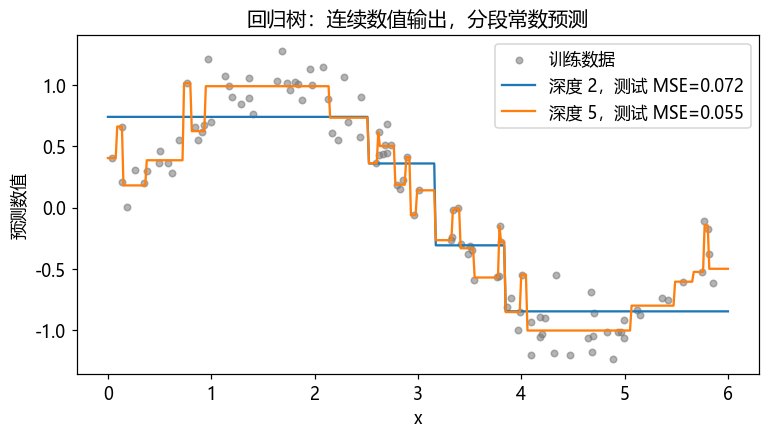

In [4]:

# 一维回归小例子：输入位置，输出连续数值，观察预测曲线的阶梯形状。
# 调整数组形状，将图像展开为样本或将预测还原为图像。
x_reg = np.sort(rng.uniform(0, 6, 140)).reshape(-1, 1)
# 计算并保存 y_reg，供后续数据处理、模型训练或结果展示使用。
y_reg = np.sin(x_reg[:, 0]) + rng.normal(0, 0.18, len(x_reg))
# 将样本及对应标签同步划分为训练集和测试集；stratify 用于保持类别比例。
xr_train, xr_test, yr_train, yr_test = train_test_split(x_reg, y_reg, random_state=SEED)
# 调整数组形状，将图像展开为样本或将预测还原为图像。
x_line = np.linspace(0, 6, 400).reshape(-1, 1)
# 创建画布和子图坐标轴，供后续绘图使用。
fig, ax = plt.subplots(figsize=(8, 4))
# 绘制散点；位置表示两个特征，颜色或大小用于区分类别、权重或指定样本。
ax.scatter(xr_train[:, 0], yr_train, s=18, color='#777777', alpha=0.55, label='训练数据')
# 循环流程：逐个设置树的最大深度，训练模型并展示预测结果，比较模型复杂度的影响。
for depth in [2, 5]:
    reg = DecisionTreeRegressor(criterion='squared_error', max_depth=depth, random_state=SEED)
    reg.fit(xr_train, yr_train)
    mse = mean_squared_error(yr_test, reg.predict(xr_test))
    ax.plot(x_line[:, 0], reg.predict(x_line), label=f'深度 {depth}，测试 MSE={mse:.3f}')
# 设置子图标题、坐标轴标签或显示范围。
ax.set(xlabel='x', ylabel='预测数值', title='回归树：连续数值输出，分段常数预测')
# 显示曲线或散点的图例，说明各组数据的含义。
ax.legend()
# 显示当前绘制的图形。
plt.show()

## 实验 2｜树结构与决策边界
**观察：**同一棵树的节点条件如何对应平面切割；指定样本经过哪些节点。

树结构用 sklearn 自带的 `plot_tree`。边界也可用 sklearn 的 `DecisionBoundaryDisplay`；本实验使用“网格预测 + Matplotlib”，便于后面复用到手写集成模型。
文字规则可用 `export_text`；无需额外安装 Graphviz。

先看深度 3 的完整树，再比较不同深度的边界。

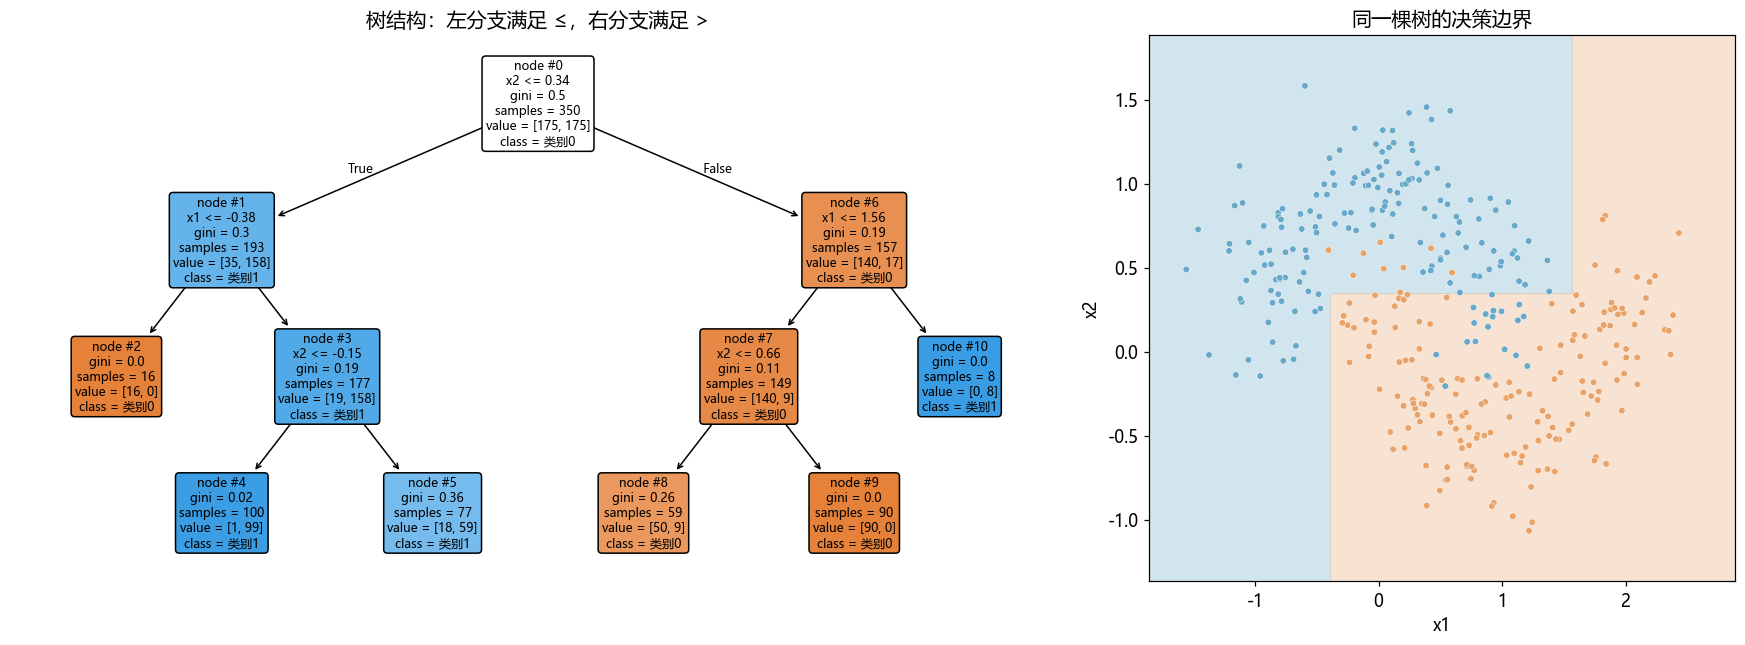

In [5]:

# 构造覆盖数据范围的网格；网格上的预测类别决定背景颜色。
# 构建二维坐标网格，供模型逐点预测并绘制分类区域。
x1, x2 = np.meshgrid(
    np.linspace(X[:, 0].min()-0.3, X[:, 0].max()+0.3, 180),
    np.linspace(X[:, 1].min()-0.3, X[:, 1].max()+0.3, 150)
)
# 将数组展平为一维，方便按样本索引或遍历。
grid = np.c_[x1.ravel(), x2.ravel()]


# 函数作用：在全局二维网格上调用预测函数，将类别绘成背景色，再叠加样本点。
def draw_boundary(ax, predict, title, points=X_train, labels=y_train, sizes=18):
    """predict 接收二维特征，返回 0/1 类别；同时支持 sklearn 和自定义预测函数。"""
    # 调整数组形状，将图像展开为样本或将预测还原为图像。
    z = predict(grid).reshape(x1.shape)
    # 执行当前数据处理操作，为后续实验准备结果。
    ax.contourf(x1, x2, z, levels=[-0.5, 0.5, 1.5], cmap=CMAP, alpha=0.3)
    # 绘制散点；位置表示两个特征，颜色或大小用于区分类别、权重或指定样本。
    ax.scatter(points[:, 0], points[:, 1], c=labels, cmap=CMAP,
               vmin=0, vmax=1, s=sizes, edgecolor='white', linewidth=0.3)
    # 设置子图标题、坐标轴标签或显示范围。
    ax.set(title=title, xlabel='x1', ylabel='x2', xlim=(x1.min(), x1.max()), ylim=(x2.min(), x2.max()))

# 创建画布和子图坐标轴，供后续绘图使用。
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.8, 1]})
# 绘制决策树节点、分裂阈值及类别信息。
plot_tree(tree, feature_names=['x1', 'x2'], class_names=['类别0', '类别1'],
          filled=True, rounded=True, node_ids=True, precision=2, fontsize=8, ax=axes[0])
# 设置当前子图的标题，说明图中展示的内容。
axes[0].set_title('树结构：左分支满足 ≤，右分支满足 >')
# 调用边界绘图函数，展示当前弱分类器或集成模型的分类区域。
draw_boundary(axes[1], tree.predict, '同一棵树的决策边界')
# 自动调整子图间距，减少标题和坐标标签重叠。
plt.tight_layout()
# 显示当前绘制的图形。
plt.show()

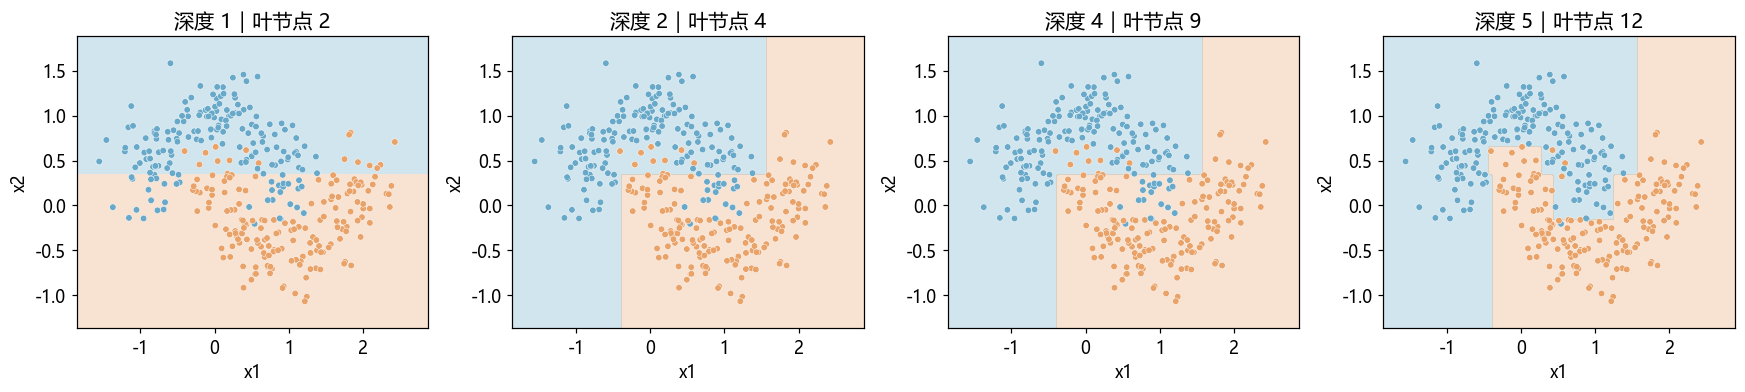

样本坐标： [ 1.05616229 -0.45061916] 真实类别： 1
节点 0：x2=-0.451，阈值=0.340 → 左分支
节点 1：x1=1.056，阈值=-0.382 → 右分支
节点 3：x2=-0.451，阈值=-0.154 → 左分支
到达叶节点 4，预测类别=1


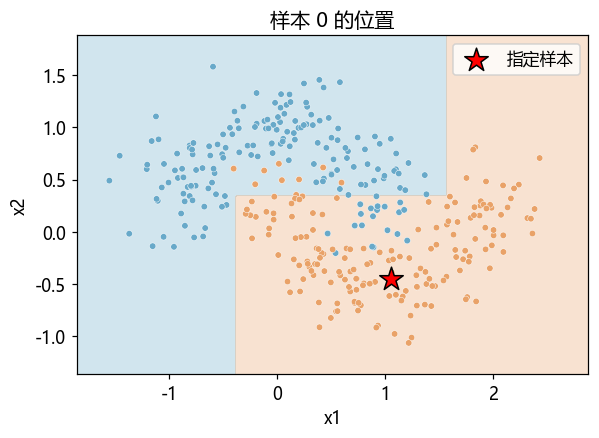

In [17]:

# 比较深度时保留相同数据、随机种子和最小叶节点设置。
# 创建画布和子图坐标轴，供后续绘图使用。
fig, axes = plt.subplots(1, 4, figsize=(16, 3.7))
# 循环流程：依次执行 zip、DecisionTreeClassifier、fit、draw_boundary、get_n_leaves，完成该组实验操作。
for ax, depth in zip(axes, [1, 2, 4, 5]):
    model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=5, random_state=SEED)
    model.fit(X_train, y_train)
    draw_boundary(ax, model.predict, f'深度 {depth}｜叶节点 {model.get_n_leaves()}')
# 自动调整子图间距，减少标题和坐标标签重叠。
plt.tight_layout()
# 显示当前绘制的图形。
plt.show()

# 追踪一个测试样本：打印沿途判断条件与最终叶节点编号。
SAMPLE_ID = 0  # 可以修改这个编号，观察其他样本。
# 取出指定测试样本，保留二维形状以满足模型输入要求。
sample = X_test[SAMPLE_ID:SAMPLE_ID+1]
# 取得样本从根节点到叶节点经过的节点编号。
path = tree.decision_path(sample).indices
# 返回样本最终落入的叶节点编号。
leaf_id = tree.apply(sample)[0]
# 输出当前实验的参数、数据规模或评估结果。
print('样本坐标：', sample[0], '真实类别：', y_test[SAMPLE_ID])
# 循环流程：沿样本的决策路径逐节点读取特征和阈值，打印分支判断，直到到达预测叶节点。
for node in path:
    if node == leaf_id:
        print(f'到达叶节点 {node}，预测类别={tree.predict(sample)[0]}')
    else:
        feature = tree.tree_.feature[node]
        threshold = tree.tree_.threshold[node]
        side = '左分支' if sample[0, feature] <= threshold else '右分支'
        print(f'节点 {node}：x{feature+1}={sample[0,feature]:.3f}，阈值={threshold:.3f} → {side}')
# 创建画布和子图坐标轴，供后续绘图使用。
fig, ax = plt.subplots(figsize=(6, 4))
# 调用边界绘图函数，展示当前弱分类器或集成模型的分类区域。
draw_boundary(ax, tree.predict, f'样本 {SAMPLE_ID} 的位置')
# 绘制散点；位置表示两个特征，颜色或大小用于区分类别、权重或指定样本。
ax.scatter(*sample[0], marker='*', s=260, c='red', edgecolor='black', label='指定样本')
# 显示曲线或散点的图例，说明各组数据的含义。
ax.legend()
# 显示当前绘制的图形。
plt.show()

## 实验 3｜动漫图像轮廓逼近
**观察：**树深度增加后，人物轮廓如何逐步细化，需要多少叶节点。

输入只有像素坐标 `(u, v)`，标签为人物 1／背景 0；RGB 只用来准备标签，不作为模型特征。只训练部分像素，再预测整张图。留出像素评估只代表同一张图内的效果，不代表能分割新图片。

可将 `IMAGE_PATH` 改成自己的透明背景 PNG；有透明通道时优先用透明度生成标签。

In [7]:

# 内嵌课件图片，保证离线运行；无需修改此单元格。
# 保存 Base64 编码的内嵌图片，解码后可直接用于离线实验。
ANIME_PNG = '...'

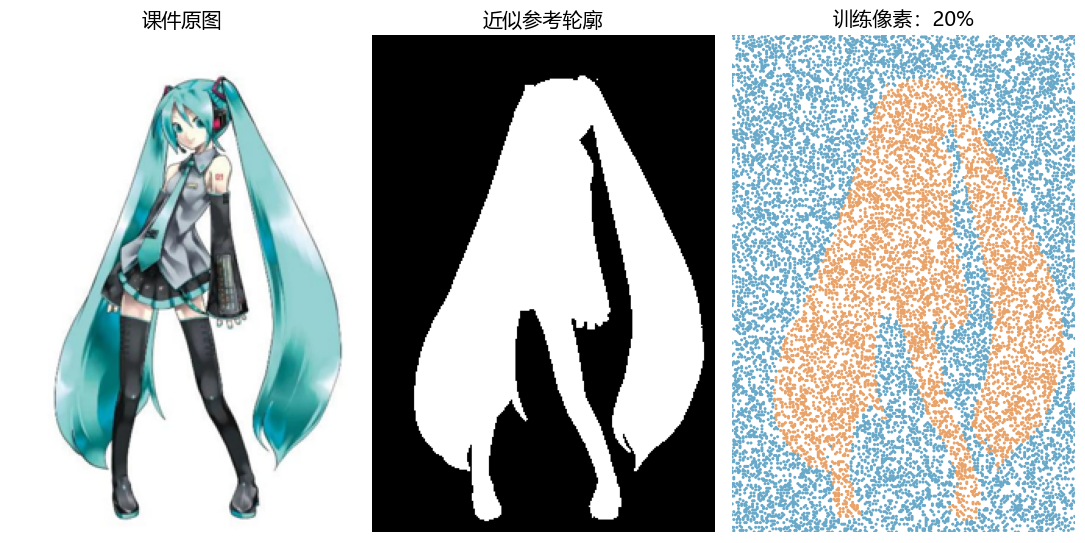

In [8]:

IMAGE_PATH = None  # 示例：'my_character.png'；None 表示使用课件图片。
# 计算并保存 image，供后续数据处理、模型训练或结果展示使用。
image = Image.open(IMAGE_PATH) if IMAGE_PATH else Image.open(io.BytesIO(base64.b64decode(ANIME_PNG)))
# 转换图像颜色模式，为颜色通道或掩膜处理做准备。
image = image.convert('RGBA')
image.thumbnail((220, 320))  # 控制像素数，保证课堂运行速度。
# 计算并保存 rgba，供后续数据处理、模型训练或结果展示使用。
rgba = np.asarray(image)
# 计算并保存 rgb，供后续数据处理、模型训练或结果展示使用。
rgb = rgba[:, :, :3]
# 计算并保存 alpha，供后续数据处理、模型训练或结果展示使用。
alpha = rgba[:, :, 3]

# 优先使用真实透明度；白底图则提取与边框连通的近白色背景。
# 分支流程：依次执行 min、zeros_like、binary_propagation，完成该组实验操作。
if alpha.min() < 255:
    mask = alpha > 127
else:
    white = np.min(rgb, axis=2) > 240
    border = np.zeros_like(white)
    border[[0, -1], :] = white[[0, -1], :]
    border[:, [0, -1]] = white[:, [0, -1]]
    background = ndimage.binary_propagation(border, mask=white)
    mask = ~background
# 检查实验前提是否成立；不满足时立即报错，避免继续使用无效数据。
assert 0 < mask.mean() < 1, '请提供同时包含人物和背景的图片。'

# 每一个像素成为一个样本；坐标归一化只为便于读数，并非树模型的要求。
# 计算并保存 (height, width)，供后续数据处理、模型训练或结果展示使用。
height, width = mask.shape
# 生成每个像素对应的行、列坐标。
v, u = np.indices(mask.shape)
# 将数组展平为一维，方便按样本索引或遍历。
X_pixel = np.c_[u.ravel() / max(width-1, 1), v.ravel() / max(height-1, 1)]
# 将数组展平为一维，方便按样本索引或遍历。
y_pixel = mask.ravel().astype(int)
# 将样本及对应标签同步划分为训练集和测试集；stratify 用于保持类别比例。
idx_train, idx_hold = train_test_split(np.arange(len(y_pixel)), train_size=0.2,
                                     stratify=y_pixel, random_state=SEED)
# 创建画布和子图坐标轴，供后续绘图使用。
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
# 将数组显示为图像，直观查看原图、掩膜或预测区域。
# 设置当前子图的标题，说明图中展示的内容。
axes[0].imshow(image); axes[0].set_title('课件原图')
# 将数组显示为图像，直观查看原图、掩膜或预测区域。
# 设置当前子图的标题，说明图中展示的内容。
axes[1].imshow(mask, cmap='gray', vmin=0, vmax=1); axes[1].set_title('近似参考轮廓')
# 绘制散点；位置表示两个特征，颜色或大小用于区分类别、权重或指定样本。
axes[2].scatter(X_pixel[idx_train, 0], X_pixel[idx_train, 1], c=y_pixel[idx_train],
                cmap=CMAP, s=1, vmin=0, vmax=1)
# 设置子图标题、坐标轴标签或显示范围。
axes[2].set(xlim=(0,1), ylim=(1,0), title='训练像素：20%')
# 设置坐标轴显示比例，保持图像的空间比例。
axes[2].set_aspect(height/width)
# 循环流程：隐藏各子图坐标轴，让图像和分割结果更清晰。
for ax in axes: ax.axis('off')
# 自动调整子图间距，减少标题和坐标标签重叠。
# 显示当前绘制的图形。
plt.tight_layout(); plt.show()

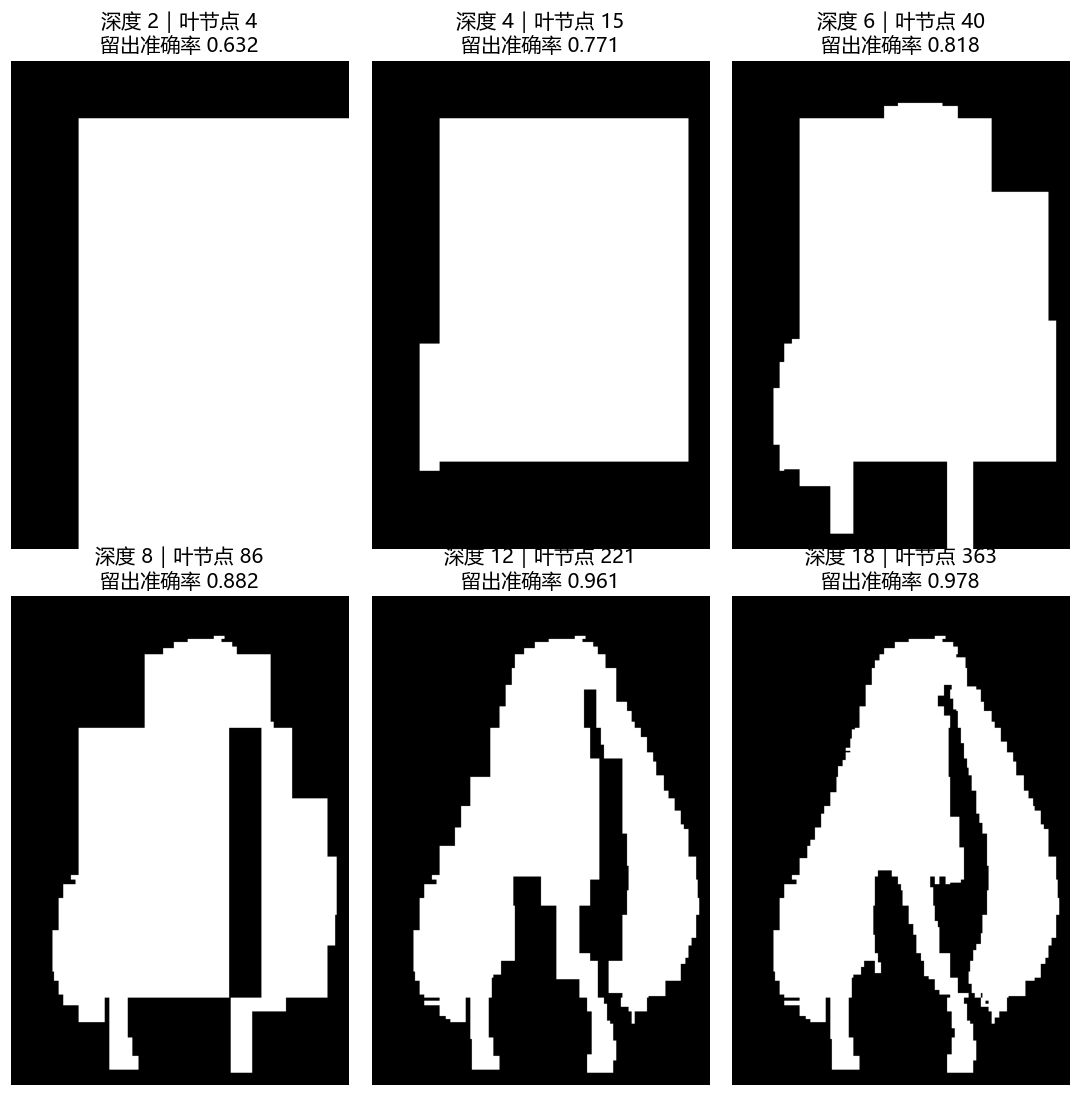

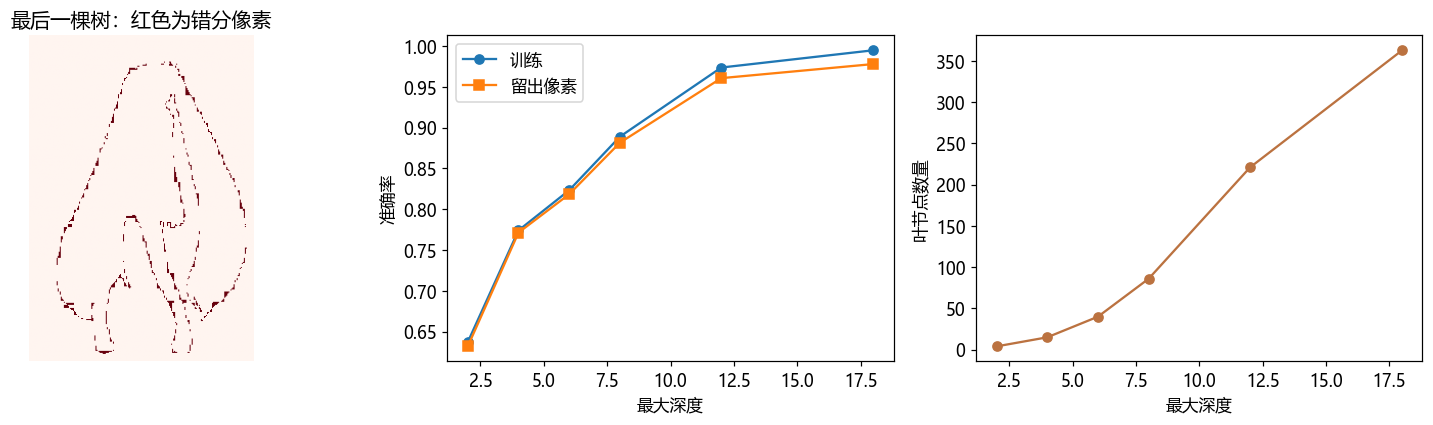

In [9]:

# 准备 depths，保存后续实验使用的配置、模型或结果记录。
depths = [2, 4, 6, 8, 12, 18]
# 准备 pixel_rows，保存后续实验使用的配置、模型或结果记录。
pixel_rows = []
# 创建画布和子图坐标轴，供后续绘图使用。
fig, axes = plt.subplots(2, 3, figsize=(10, 10))
# 循环流程：依次执行 zip、ravel、DecisionTreeClassifier、fit、predict、accuracy_score、append、imshow、set_title、axis、reshape、get_n_leaves，完成该组实验操作。
for ax, depth in zip(axes.ravel(), depths):
    pixel_tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=2, random_state=SEED)
    pixel_tree.fit(X_pixel[idx_train], y_pixel[idx_train])
    prediction = pixel_tree.predict(X_pixel)
    train_acc = accuracy_score(y_pixel[idx_train], prediction[idx_train])
    hold_acc = accuracy_score(y_pixel[idx_hold], prediction[idx_hold])
    pixel_rows.append({'深度': depth, '叶节点数': pixel_tree.get_n_leaves(),
                       '训练准确率': train_acc, '留出像素准确率': hold_acc})
    ax.imshow(prediction.reshape(mask.shape), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'深度 {depth}｜叶节点 {pixel_tree.get_n_leaves()}\n留出准确率 {hold_acc:.3f}')
    ax.axis('off')
# 自动调整子图间距，减少标题和坐标标签重叠。
# 显示当前绘制的图形。
plt.tight_layout(); plt.show()
# 将实验数据或评估记录整理为表格。
pixel_results = pd.DataFrame(pixel_rows)

# 单独画最后一棵树的错误位置；错误是相对于自动生成的参考标签计算的。
# 创建画布和子图坐标轴，供后续绘图使用。
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
# 将数组显示为图像，直观查看原图、掩膜或预测区域。
axes[0].imshow((prediction != y_pixel).reshape(mask.shape), cmap='Reds', vmin=0, vmax=1)
# 设置当前子图的标题，说明图中展示的内容。
# 设置坐标轴显示方式；off 表示隐藏坐标轴。
axes[0].set_title('最后一棵树：红色为错分像素'); axes[0].axis('off')
# 将横纵坐标连接成曲线，用于比较预测结果或指标变化。
axes[1].plot(depths, pixel_results['训练准确率'], 'o-', label='训练')
# 将横纵坐标连接成曲线，用于比较预测结果或指标变化。
axes[1].plot(depths, pixel_results['留出像素准确率'], 's-', label='留出像素')
# 设置子图标题、坐标轴标签或显示范围。
# 显示曲线或散点的图例，说明各组数据的含义。
axes[1].set(xlabel='最大深度', ylabel='准确率'); axes[1].legend()
# 将横纵坐标连接成曲线，用于比较预测结果或指标变化。
axes[2].plot(depths, pixel_results['叶节点数'], 'o-', color='#bb7240')
# 设置子图标题、坐标轴标签或显示范围。
axes[2].set(xlabel='最大深度', ylabel='叶节点数量')
# 自动调整子图间距，减少标题和坐标标签重叠。
# 显示当前绘制的图形。
plt.tight_layout(); plt.show()

## 实验 4｜Bagging、AdaBoost、Stacking 的调用
**观察：**同一数据和划分下，三种集成的边界与测试表现。

| 方法 | 主要设置 | 可查看的内部结果 |
|---|---|---|
| Bagging | `estimator`、`n_estimators`、`max_samples`、`bootstrap` | `estimators_`、`estimators_samples_` |
| AdaBoost | `estimator`、`n_estimators`、`learning_rate` | `estimators_`、`estimator_weights_`、`estimator_errors_`、`staged_predict` |
| Stacking | `estimators`、`final_estimator`、`cv`、`stack_method` | `estimators_`、`final_estimator_`、`transform` |

这是调用演示，不是调参后的模型排名；单次实验不保证某种集成一定更好。

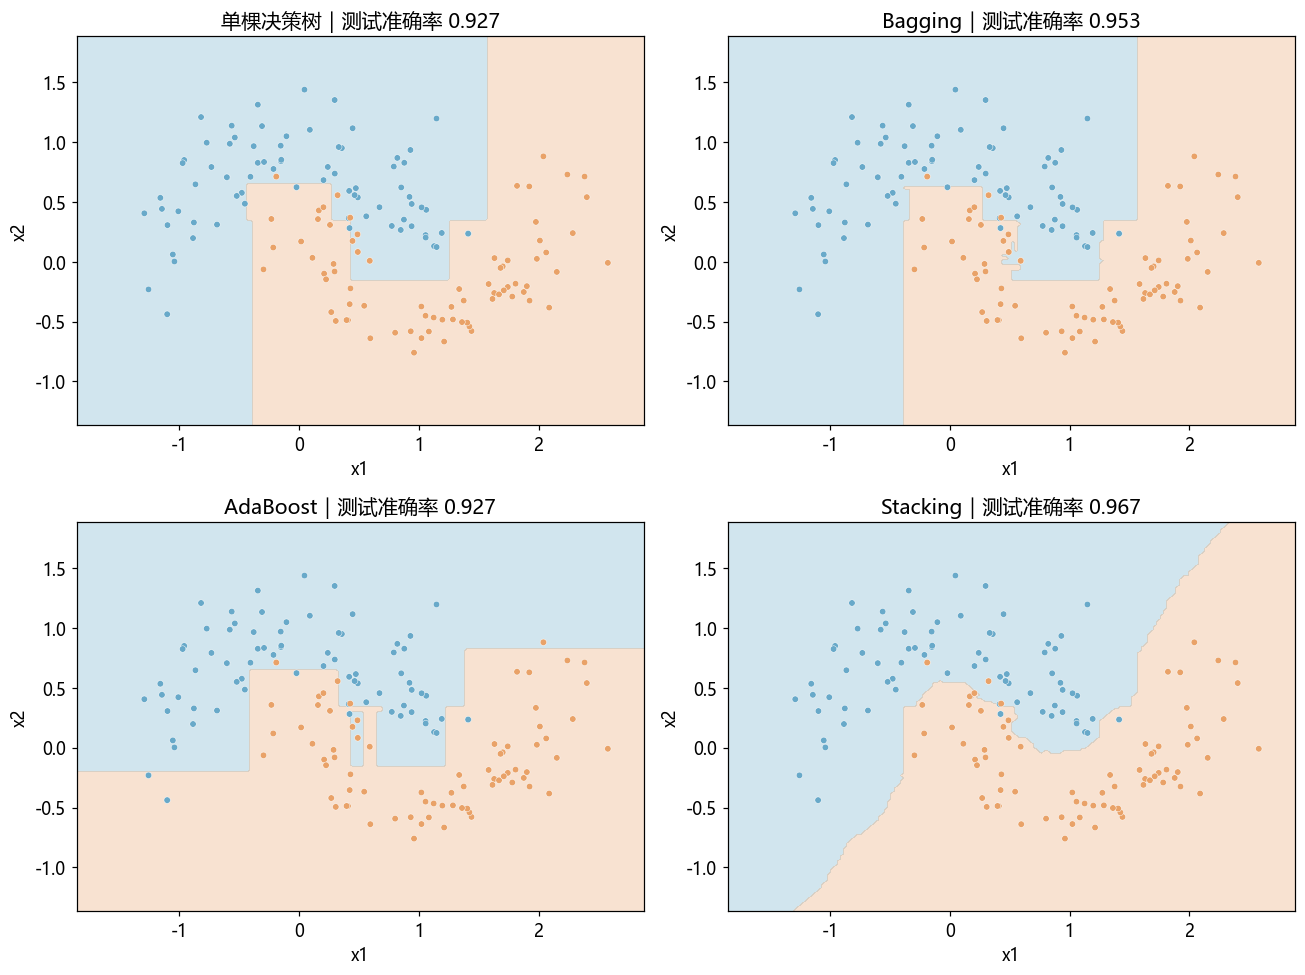

,模型,训练准确率,测试准确率
0,单棵决策树,0.989,0.927
1,Bagging,0.989,0.953
2,AdaBoost,0.991,0.927
3,Stacking,0.963,0.967


In [10]:

# 兼容旧版本的 base_estimator 参数名；新版本使用 estimator。

# 函数作用：检查构造器使用 estimator 还是 base_estimator，返回兼容当前版本的基学习器参数。
def estimator_kw(cls, base):
    # 计算并保存 key，供后续数据处理、模型训练或结果展示使用。
    key = 'estimator' if 'estimator' in inspect.signature(cls).parameters else 'base_estimator'
    # 准备 ，保存后续实验使用的配置、模型或结果记录。
    return {key: base}

# 创建 Bagging 分类器，对训练数据重复抽样训练多个基模型并投票。
bag = BaggingClassifier(
    **estimator_kw(BaggingClassifier, DecisionTreeClassifier(min_samples_leaf=2)),
    n_estimators=40, max_samples=0.8, bootstrap=True, random_state=SEED, n_jobs=1
)

# 旧版本需显式选 SAMME；新版本已经只保留离散算法，不再传 algorithm。
# 创建分类决策树；max_depth 限制深度，min_samples_leaf 限制叶节点最少样本数。
ada_kw = estimator_kw(AdaBoostClassifier, DecisionTreeClassifier(max_depth=1))
# 计算并保存 algorithm_param，供后续数据处理、模型训练或结果展示使用。
algorithm_param = inspect.signature(AdaBoostClassifier).parameters.get('algorithm')
# 分支流程：依次执行 ，完成该组实验操作。
if algorithm_param is not None and algorithm_param.default != 'deprecated':
    ada_kw['algorithm'] = 'SAMME'
# 创建 AdaBoost 分类器，逐轮关注分错样本并加权组合弱分类器。
ada = AdaBoostClassifier(**ada_kw, n_estimators=60, learning_rate=1.0, random_state=SEED)

# Stacking 的第二层使用五折折外预测训练；标准化封装在各自流水线中。
# 创建分类决策树；max_depth 限制深度，min_samples_leaf 限制叶节点最少样本数。
base_models = [
    ('tree', DecisionTreeClassifier(max_depth=3, random_state=SEED)),
    ('knn', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))),
    ('logistic', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))
]
# 设置分层交叉验证，让每折保持近似类别比例。
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
# 创建两层集成分类器，用基模型的交叉验证预测训练最终分类器。
stack = StackingClassifier(estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000), cv=cv,
    stack_method='predict_proba', passthrough=False, n_jobs=1)
# 创建分类决策树；max_depth 限制深度，min_samples_leaf 限制叶节点最少样本数。
models = {'单棵决策树': DecisionTreeClassifier(min_samples_leaf=2, random_state=SEED),
          'Bagging': bag, 'AdaBoost': ada, 'Stacking': stack}
# 准备 rows，保存后续实验使用的配置、模型或结果记录。
rows = []
# 创建画布和子图坐标轴，供后续绘图使用。
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
# 循环流程：依次执行 zip、ravel、items、fit、score、append、draw_boundary，完成该组实验操作。
for ax, (name, model) in zip(axes.ravel(), models.items()):
    model.fit(X_train, y_train)
    score = model.score(X_test, y_test)
    rows.append({'模型': name, '训练准确率': model.score(X_train, y_train), '测试准确率': score})
    draw_boundary(ax, model.predict, f'{name}｜测试准确率 {score:.3f}', X_test, y_test)
# 自动调整子图间距，减少标题和坐标标签重叠。
# 显示当前绘制的图形。
plt.tight_layout(); plt.show()
# 在 Notebook 中展示结果表格，便于查看和比较。
display(pd.DataFrame(rows).round(3))

成员树 1：抽样 280 次，涉及 191 个不同样本
成员树 2：抽样 280 次，涉及 196 个不同样本
成员树 3：抽样 280 次，涉及 184 个不同样本


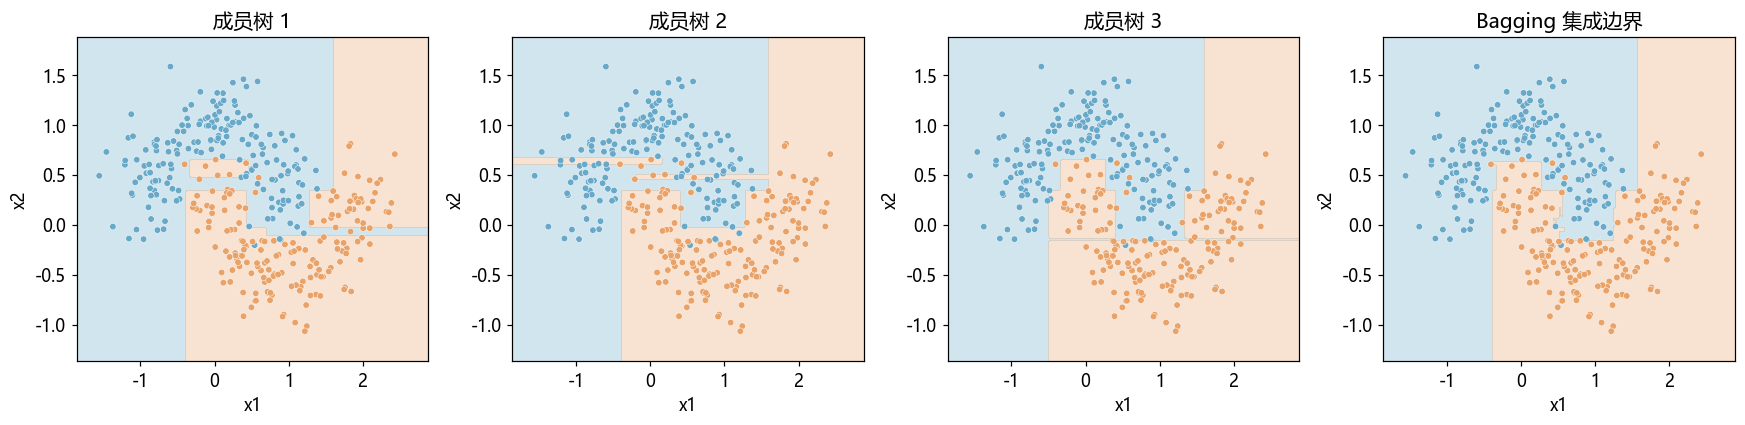

In [11]:

# 查看 Bagging 中三棵成员树，以及它们共同形成的预测。
# 创建画布和子图坐标轴，供后续绘图使用。
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
# 循环流程：取出三棵 Bagging 成员树及各自使用的特征，分别绘制分类边界以比较成员差异。
for j in range(3):
    member = bag.estimators_[j]
    features = bag.estimators_features_[j]
    draw_boundary(axes[j], lambda z, m=member, f=features: m.predict(z[:, f]), f'成员树 {j+1}')
    indices = bag.estimators_samples_[j]
    print(f'成员树 {j+1}：抽样 {len(indices)} 次，涉及 {len(np.unique(indices))} 个不同样本')
# 调用边界绘图函数，展示当前弱分类器或集成模型的分类区域。
draw_boundary(axes[3], bag.predict, 'Bagging 集成边界')
# 自动调整子图间距，减少标题和坐标标签重叠。
# 显示当前绘制的图形。
plt.tight_layout(); plt.show()

In [12]:

# transform 展示预测时的第二层输入：二分类时每个基模型保留 P(类别1) 一列。
# 生成 Stacking 元特征，供第二层模型使用。
meta_test = stack.transform(X_test)
# 计算并保存 columns，供后续数据处理、模型训练或结果展示使用。
columns = [name + '：P(1)' for name, _ in base_models]
# 将实验数据或评估记录整理为表格。
meta_preview = pd.DataFrame(meta_test[:6], columns=columns)
# 使用训练好的模型预测输入样本的类别或连续数值。
meta_preview['最终类别'] = stack.predict(X_test[:6])
# 计算并保存 meta_preview['真实类别']，供后续数据处理、模型训练或结果展示使用。
meta_preview['真实类别'] = y_test[:6]
# 在 Notebook 中展示结果表格，便于查看和比较。
display(meta_preview.round(3))

# 为观察训练时的数据，重新生成相同五折划分下的折外预测。
# 不要把 stack.transform(X_train) 当作第二层训练时使用的折外预测。
# 计算并保存 meta_oof，供后续数据处理、模型训练或结果展示使用。
meta_oof = np.column_stack([
    cross_val_predict(clone(model), X_train, y_train, cv=cv,
                      method='predict_proba', n_jobs=1)[:, 1]
    for _, model in base_models
])
# 输出当前实验的参数、数据规模或评估结果。
print('第二层训练输入形状：', meta_oof.shape)
# 在 Notebook 中展示结果表格，便于查看和比较。
display(pd.DataFrame(meta_oof[:6], columns=columns).round(3))

,tree：P(1),knn：P(1),logistic：P(1),最终类别,真实类别
0,0.990,1.000,0.974,1,1
1,0.990,1.000,0.990,1,1
2,0.153,0.200,0.177,0,0
3,0.000,0.000,0.098,0,0
4,0.766,1.000,0.973,1,1
5,0.153,0.133,0.073,0,0


第二层训练输入形状： (350, 3)


,tree：P(1),knn：P(1),logistic：P(1)
0,0.741,0.800,0.684
1,0.000,0.000,0.011
2,0.149,0.067,0.514
3,0.772,0.333,0.744
4,0.171,0.067,0.546
5,0.977,1.000,0.984


## 实验 5｜AdaBoost 逐轮观察
**观察：**弱分类器输出、分类器权重、样本权重和组合边界怎样变化。

先直接读取 sklearn 保存的各轮结果；再用简短循环保存课件版本的完整样本权重历史。
本实验手写循环中 `h_t` 输出 ±1，`F_t` 为实数分数，最终类别按分数正负确定。sklearn 的二分类 SAMME 分类器权重采用另一尺度，不要直接把它当作课件中的半对数系数。

,轮数,加权错误率,sklearn分类器权重
0,1,0.1486,1.7458
1,2,0.2443,1.1295
2,3,0.2310,1.2028
3,4,0.2424,1.1396
4,5,0.3188,0.7594
5,6,0.3367,0.6782
6,7,0.3157,0.7737
7,8,0.3082,0.8087
8,9,0.3152,0.7761
9,10,0.3392,0.6667


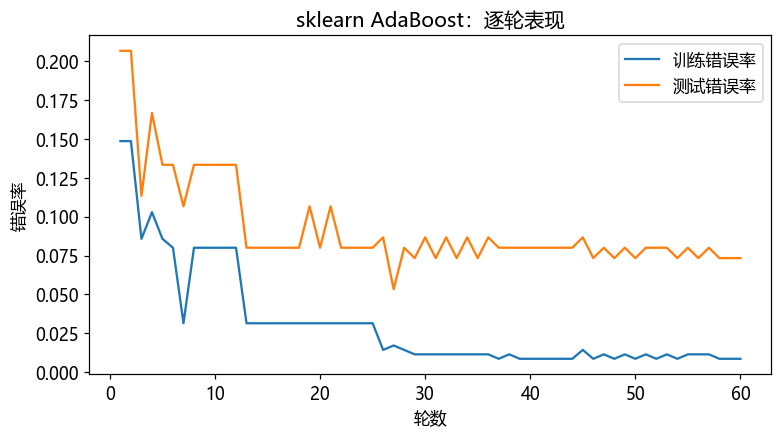

In [13]:

# sklearn 只保留实际训练出的分类器；提前停止时数量可能小于 n_estimators。
# 计算并保存 n_rounds，供后续数据处理、模型训练或结果展示使用。
n_rounds = len(ada.estimators_)
# 将实验数据或评估记录整理为表格。
ada_table = pd.DataFrame({'轮数': np.arange(1, n_rounds+1),
    '加权错误率': ada.estimator_errors_[:n_rounds],
    'sklearn分类器权重': ada.estimator_weights_[:n_rounds]})
# 在 Notebook 中展示结果表格，便于查看和比较。
display(ada_table.head(10).round(4))

# staged_predict 逐轮给出当前集成预测，不需要为每个轮数重新训练。
# 计算并保存 train_errors，供后续数据处理、模型训练或结果展示使用。
train_errors = [1-accuracy_score(y_train, p) for p in ada.staged_predict(X_train)]
# 计算并保存 test_errors，供后续数据处理、模型训练或结果展示使用。
test_errors = [1-accuracy_score(y_test, p) for p in ada.staged_predict(X_test)]
# 创建画布和子图坐标轴，供后续绘图使用。
fig, ax = plt.subplots(figsize=(8, 4))
# 将横纵坐标连接成曲线，用于比较预测结果或指标变化。
ax.plot(np.arange(1,n_rounds+1), train_errors, label='训练错误率')
# 将横纵坐标连接成曲线，用于比较预测结果或指标变化。
ax.plot(np.arange(1,n_rounds+1), test_errors, label='测试错误率')
# 设置子图标题、坐标轴标签或显示范围。
# 显示曲线或散点的图例，说明各组数据的含义。
ax.set(xlabel='轮数', ylabel='错误率', title='sklearn AdaBoost：逐轮表现'); ax.legend()
# 显示当前绘制的图形。
plt.show()

In [14]:

# 使用同一训练集；标签转成 ±1，与课件中的代码记号对应。
# 把 0/1 标签转换为 -1/+1，便于使用 AdaBoost 的指数损失和权重更新公式。
y_pm = 2 * y_train - 1
# 设置手动 AdaBoost 的最大训练轮数。
T = 30
# 创建初值相同的数组，使所有样本具有相同的初始权重。
weights = np.full(len(y_train), 1 / len(y_train))
# 创建全零数组，用于初始化集成分数。
F_train = np.zeros(len(y_train))
# 创建全零数组，用于初始化集成分数。
F_test = np.zeros(len(y_test))
# 准备 history，保存后续实验使用的配置、模型或结果记录。
history = []

# 循环流程：按当前样本权重训练树桩，计算加权错误率和学习器权重，提高错分样本权重并归一化，保存各轮结果。
for t in range(T):
    # 1. 用当前样本权重训练本轮弱分类器；这里只允许一次切分。
    weak = DecisionTreeClassifier(max_depth=1, random_state=SEED+t)
    weak.fit(X_train, y_pm, sample_weight=weights)
    h_train = weak.predict(X_train)
    wrong = h_train != y_pm
    error = np.sum(weights[wrong])

    # 2. 无有效改进时停止；错误率为零时用有限数值保护，并在记录后停止。
    if error >= 0.5 - 1e-12:
        print(f'第 {t+1} 轮无有效弱分类器，停止。')
        break
    safe_error = np.clip(error, 1e-12, 1-1e-12)
    alpha_t = 0.5 * np.log((1-safe_error) / safe_error)

    # 3. 累加实数分类分数；零分数统一归为类别 1，避免输出第三种标签。
    F_train += alpha_t * h_train
    F_test += alpha_t * weak.predict(X_test)

    # 4. 更新样本权重并归一化，同时保留更新前后的副本用于画图。
    next_weights = weights * np.exp(-alpha_t * y_pm * h_train)
    next_weights /= next_weights.sum()
    history.append({'model': weak, 'alpha': alpha_t, 'error': error,
        'weights_before': weights.copy(), 'weights_after': next_weights.copy(),
        'wrong': wrong.copy(),
        'train_error': 1-accuracy_score(y_train, (F_train >= 0).astype(int)),
        'test_error': 1-accuracy_score(y_test, (F_test >= 0).astype(int)),
        'loss': np.mean(np.exp(-y_pm * F_train))})
    weights = next_weights
    if error <= 1e-12:
        print(f'第 {t+1} 轮弱分类器已完全分对，停止。')
        break

# 输出当前实验的参数、数据规模或评估结果。
print('实际完成轮数：', len(history))
# 检查实验前提是否成立；不满足时立即报错，避免继续使用无效数据。
assert len(history) > 0
# 输出当前实验的参数、数据规模或评估结果。
print('第一轮弱分类器的输出：', np.unique(history[0]['model'].predict(X_train)))
# 输出当前实验的参数、数据规模或评估结果。
print('集成分数示例：', np.round(F_train[:6], 3))

实际完成轮数： 30
第一轮弱分类器的输出： [-1  1]
集成分数示例： [ 1.798 -3.028 -1.931 -0.738 -1.931  7.21 ]


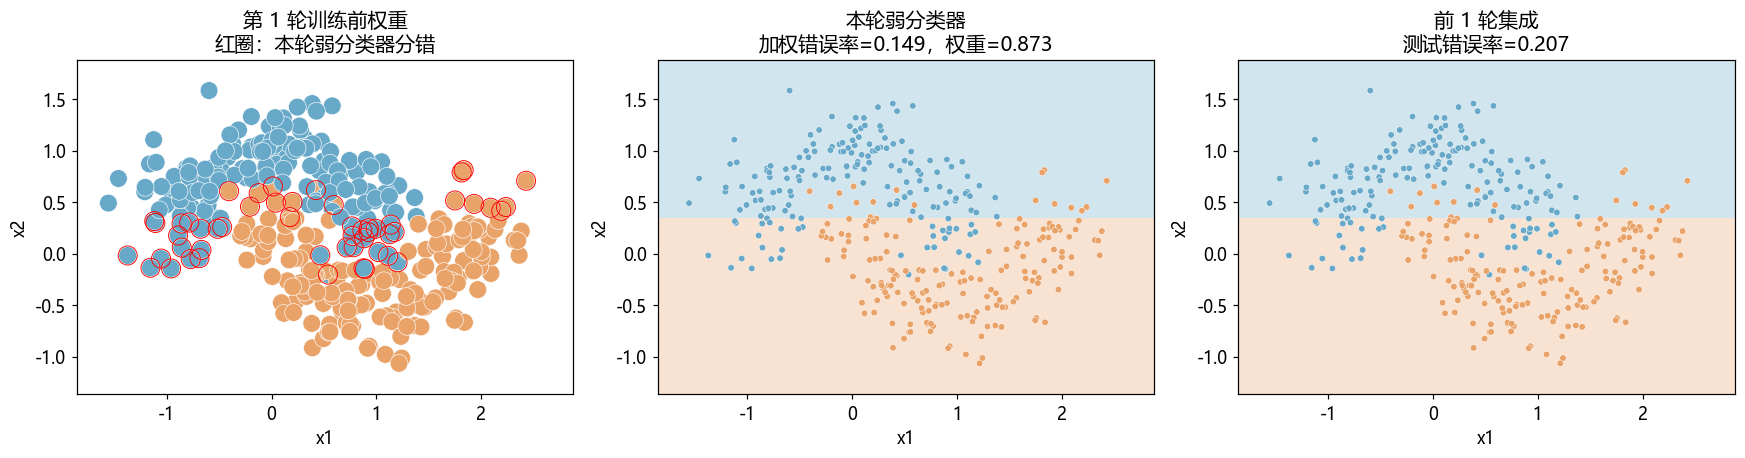

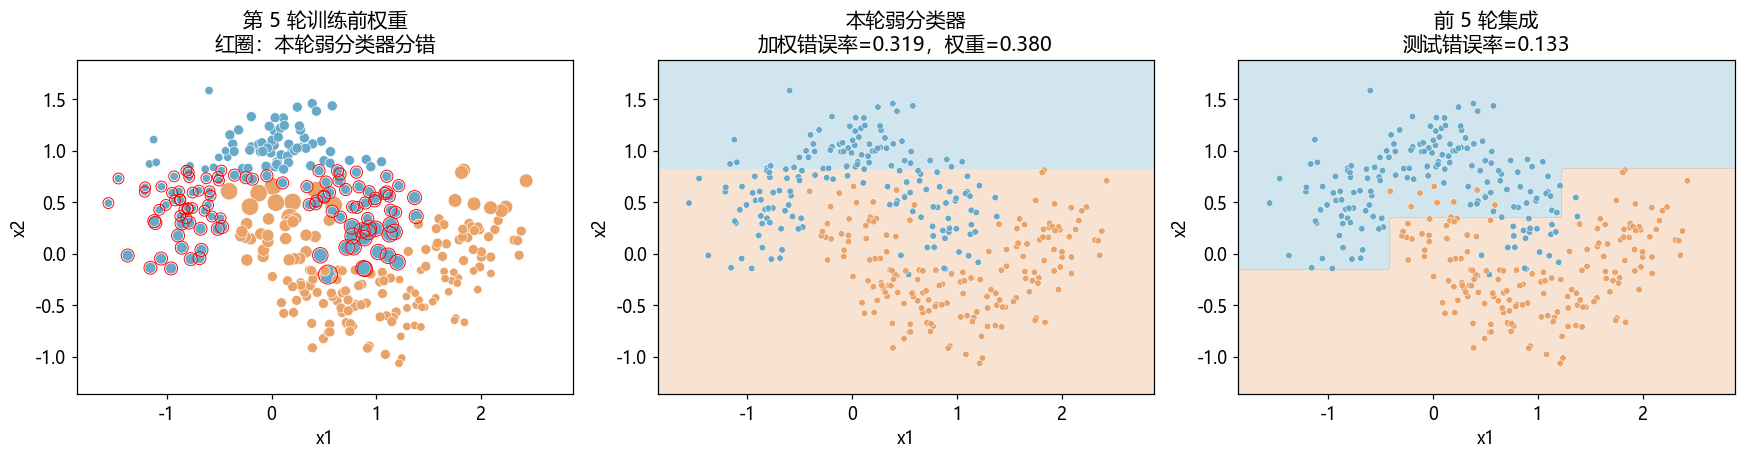

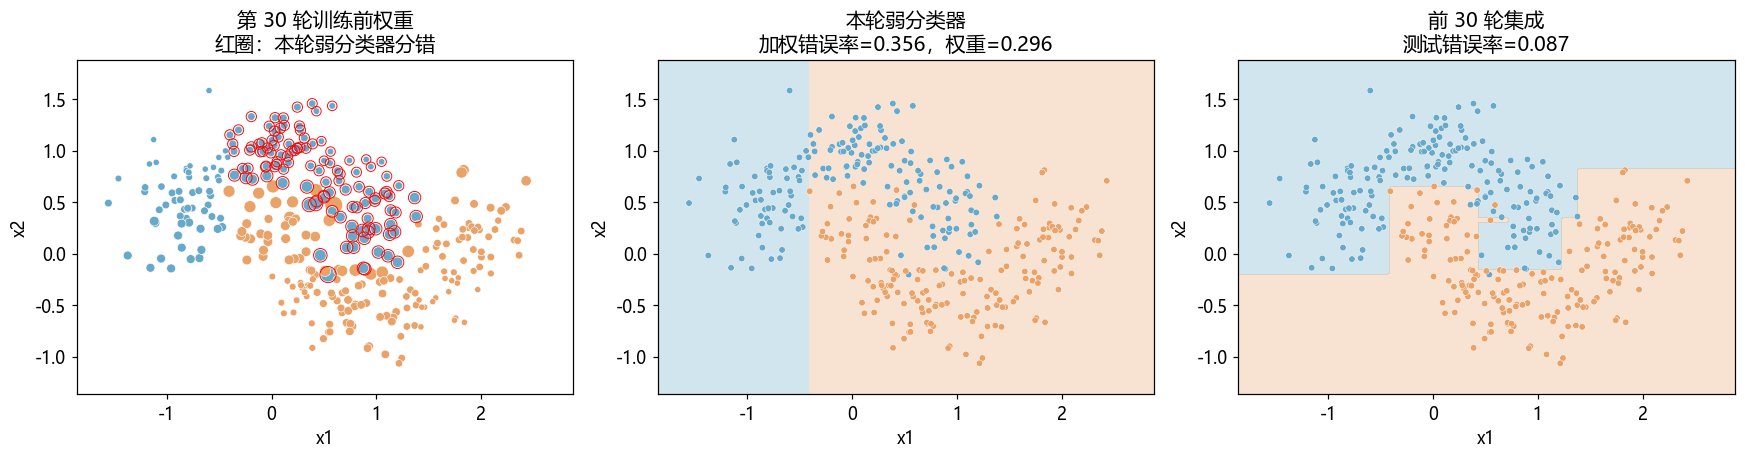

In [15]:


# 函数作用：取前 round_count 轮弱分类器，累加加权预测分数，再转换为 0/1 类别。
def ensemble_predict(z, round_count):
    # 将前 round_count 轮的加权分数相加，再转成画图用的 0/1 标签。
    # 创建全零数组，用于初始化集成分数。
    score = np.zeros(len(z))
    # 循环流程：遍历指定轮数内的弱分类器，将预测乘以该轮权重，累加为最终分类分数。
    for item in history[:round_count]:
        score += item['alpha'] * item['model'].predict(z)
    # 返回计算结果，供调用该函数的代码继续使用。
    return (score >= 0).astype(int)


# 函数作用：读取指定轮次的训练记录，展示样本权重、弱分类器和集成模型的边界。
def show_round(round_number):
    # 左图的点大小表示本轮训练前权重；红圈表示本轮弱分类器分错的点。
    # 取出指定轮次的训练记录，供绘制该轮状态使用。
    item = history[round_number-1]
    # 将样本权重映射为散点大小，让权重较大的样本更醒目。
    sizes = 15 + 120 * np.sqrt(item['weights_before'] / item['weights_before'].max())
    # 创建画布和子图坐标轴，供后续绘图使用。
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
    # 绘制散点；位置表示两个特征，颜色或大小用于区分类别、权重或指定样本。
    axes[0].scatter(X_train[:,0], X_train[:,1], c=y_train, cmap=CMAP, s=sizes,
                    edgecolor='white', linewidth=0.4)
    # 取出本轮被弱分类器分错的样本标记。
    wrong = item['wrong']
    # 绘制散点；位置表示两个特征，颜色或大小用于区分类别、权重或指定样本。
    axes[0].scatter(X_train[wrong,0], X_train[wrong,1], facecolors='none',
                    edgecolors='red', s=sizes[wrong]+20, linewidth=0.6)
    # 设置子图标题、坐标轴标签或显示范围。
    axes[0].set(title=f'第 {round_number} 轮训练前权重\n红圈：本轮弱分类器分错', xlabel='x1', ylabel='x2',
                xlim=(x1.min(), x1.max()), ylim=(x2.min(), x2.max()))
    # 调用边界绘图函数，展示当前弱分类器或集成模型的分类区域。
    draw_boundary(axes[1], lambda z: (item['model'].predict(z)+1)//2,
                  f'本轮弱分类器\n加权错误率={item["error"]:.3f}，权重={item["alpha"]:.3f}')
    # 调用边界绘图函数，展示当前弱分类器或集成模型的分类区域。
    draw_boundary(axes[2], lambda z: ensemble_predict(z, round_number),
                  f'前 {round_number} 轮集成\n测试错误率={item["test_error"]:.3f}')
    # 自动调整子图间距，减少标题和坐标标签重叠。
    # 显示当前绘制的图形。
    plt.tight_layout(); plt.show()

# 默认展示三轮，避免输出过多；可改成任意已完成的轮数。
# 循环流程：选择第 1 轮、中间轮和最后一轮，调用 show_round 展示训练状态。
for round_number in sorted(set([1, min(5, len(history)), len(history)])):
    show_round(round_number)

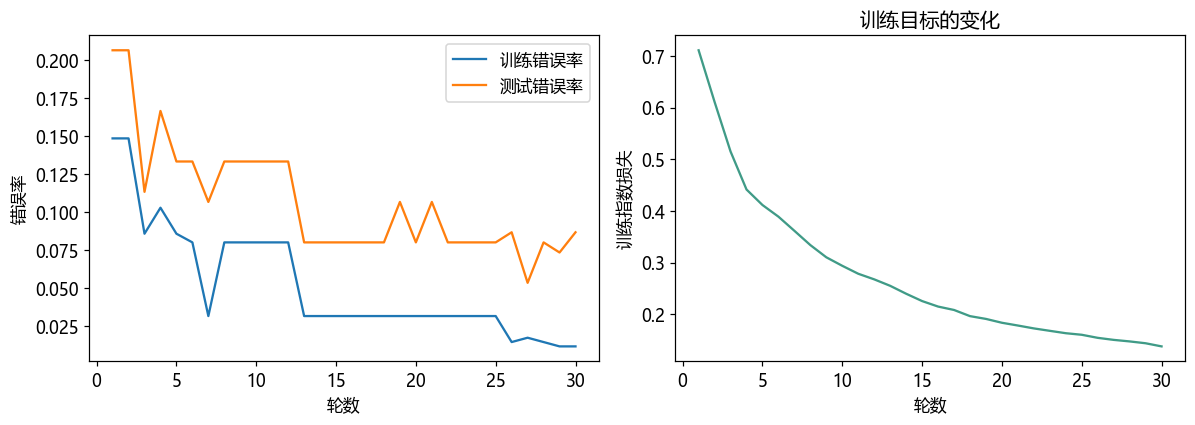

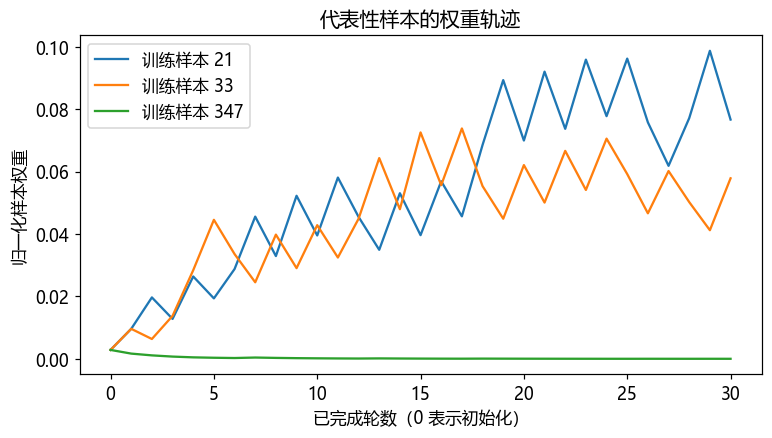

,轮数,样本编号,本轮分错,更新前,更新后
0,1,21,True,0.00286,0.00962
1,1,33,True,0.00286,0.00962
2,1,347,False,0.00286,0.00168
3,2,21,True,0.00962,0.01968
4,2,33,False,0.00962,0.00636
5,2,347,False,0.00168,0.00111
6,3,21,False,0.01968,0.01280
7,3,33,True,0.00636,0.01377
8,3,347,False,0.00111,0.00072
9,4,21,True,0.01280,0.02640


In [16]:

# 训练指数损失与分类错误率分别作图，避免把两种指标混为一谈。
# 计算并保存 rounds，供后续数据处理、模型训练或结果展示使用。
rounds = np.arange(1, len(history)+1)
# 创建画布和子图坐标轴，供后续绘图使用。
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# 将横纵坐标连接成曲线，用于比较预测结果或指标变化。
axes[0].plot(rounds, [s['train_error'] for s in history], label='训练错误率')
# 将横纵坐标连接成曲线，用于比较预测结果或指标变化。
axes[0].plot(rounds, [s['test_error'] for s in history], label='测试错误率')
# 设置子图标题、坐标轴标签或显示范围。
# 显示曲线或散点的图例，说明各组数据的含义。
axes[0].set(xlabel='轮数', ylabel='错误率'); axes[0].legend()
# 将横纵坐标连接成曲线，用于比较预测结果或指标变化。
axes[1].plot(rounds, [s['loss'] for s in history], color='#409b87')
# 设置子图标题、坐标轴标签或显示范围。
axes[1].set(xlabel='轮数', ylabel='训练指数损失', title='训练目标的变化')
# 自动调整子图间距，减少标题和坐标标签重叠。
# 显示当前绘制的图形。
plt.tight_layout(); plt.show()

# 选择最后权重较大和较小的样本，观察它们此前的权重变化。
# 计算并保存 order，供后续数据处理、模型训练或结果展示使用。
order = np.argsort(history[-1]['weights_after'])
# 准备 chosen，保存后续实验使用的配置、模型或结果记录。
chosen = [int(order[-1]), int(order[-2]), int(order[0])]
# 计算并保存 weight_matrix，供后续数据处理、模型训练或结果展示使用。
weight_matrix = np.vstack([history[0]['weights_before']] + [s['weights_after'] for s in history])
# 创建画布和子图坐标轴，供后续绘图使用。
fig, ax = plt.subplots(figsize=(8, 4))
# 循环流程：取代表性样本在各轮的权重，绘制曲线以观察权重如何随训练变化。
for idx in chosen:
    ax.plot(np.arange(len(history)+1), weight_matrix[:, idx], label=f'训练样本 {idx}')
# 设置子图标题、坐标轴标签或显示范围。
ax.set(xlabel='已完成轮数（0 表示初始化）', ylabel='归一化样本权重', title='代表性样本的权重轨迹')
# 显示曲线或散点的图例，说明各组数据的含义。
# 显示当前绘制的图形。
ax.legend(); plt.show()

# 表格直接对应“本轮是否分错”和“更新前后权重”。
# 准备 records，保存后续实验使用的配置、模型或结果记录。
records = []
# 循环流程：依次执行 enumerate、append、bool，完成该组实验操作。
for t, item in enumerate(history[:8], 1):
    for idx in chosen:
        records.append({'轮数': t, '样本编号': idx, '本轮分错': bool(item['wrong'][idx]),
                        '更新前': item['weights_before'][idx], '更新后': item['weights_after'][idx]})
# 在 Notebook 中展示结果表格，便于查看和比较。
display(pd.DataFrame(records).round(5))